<a href="https://colab.research.google.com/github/RoihansLab/Data-Mining-Project/blob/main/Clustering_AI_LLM_Arena.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import Library**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer
import joblib

# **Preprocessing**

In [2]:
df = pd.read_csv('/content/Ai_LLM_Arena.csv')
df.head()

,Unnamed: 0,ID,Rank,Model,Score,Votes,Price,Context,Arena_Category
0,0,1,1,gemini-4-argon-highGoogle · Proprietary,1525±9Preliminary,4892,$2 / $10,1M,Text_Chat
1,1,2,2,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507±8,6272,$4 / $20,1M,Text_Chat
2,2,3,3,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504±3,79415,$5 / $25,1M,Text_Chat
3,3,4,4,Anthropicclaude-fable-5-highAnthropic · Propri...,1504±4,40026,$10 / $50,1M,Text_Chat
4,4,5,5,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501±4,65192,$5 / $25,1M,Text_Chat


In [3]:
df = df.drop(columns=['ID', 'Rank'], errors='ignore')

print("✅ Kolom ID & Rank berhasil dihapus!")
print(df.info())

✅ Kolom ID & Rank berhasil dihapus!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Unnamed: 0      863 non-null    int64 
 1   Model           863 non-null    object
 2   Score           863 non-null    object
 3   Votes           863 non-null    int64 
 4   Price           725 non-null    object
 5   Context         658 non-null    object
 6   Arena_Category  863 non-null    object
dtypes: int64(2), object(5)
memory usage: 47.3+ KB
None


In [4]:
df.head()

,Unnamed: 0,Model,Score,Votes,Price,Context,Arena_Category
0,0,gemini-4-argon-highGoogle · Proprietary,1525±9Preliminary,4892,$2 / $10,1M,Text_Chat
1,1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507±8,6272,$4 / $20,1M,Text_Chat
2,2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504±3,79415,$5 / $25,1M,Text_Chat
3,3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504±4,40026,$10 / $50,1M,Text_Chat
4,4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501±4,65192,$5 / $25,1M,Text_Chat


In [5]:
df['Score'] = df['Score'].astype(str).str.split('±').str[0]
df['Score'] = pd.to_numeric(df['Score'], errors='coerce')
df[['Model', 'Score']].head()

,Model,Score
0,gemini-4-argon-highGoogle · Proprietary,1525.0
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0


In [6]:
# 1. Ambil angka Input (sebelum '/') dan buang simbol '$'
input_p = df['Price'].astype(str).str.split('/').str[0].str.replace('$', '').str.strip()

# 2. Ambil angka Output (setelah '/') dan buang simbol '$'
output_p = df['Price'].astype(str).str.split('/').str[1].str.replace('$', '').str.strip()

# 3. Hitung Rata-Rata: (Input + Output) / 2
df['Price'] = (pd.to_numeric(input_p, errors='coerce') + pd.to_numeric(output_p, errors='coerce')) / 2

# 4. Cek hasil 5 baris pertama
df[['Model', 'Score', 'Price']].head()

,Model,Score,Price
0,gemini-4-argon-highGoogle · Proprietary,1525.0,6.0
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0,12.0
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0,15.0
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0,30.0
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0,15.0


In [7]:
# 1. Konversi '1M' -> 1000000, '128K' -> 128000, dst.
def clean_context(val):
    if pd.isna(val): return None
    val_str = str(val).upper().strip()
    if 'M' in val_str:
        return float(val_str.replace('M', '')) * 1_000_000
    elif 'K' in val_str:
        return float(val_str.replace('K', '')) * 1_000
    else:
        try:
            return float(val_str)
        except:
            return None


df['Context'] = df['Context'].apply(clean_context)
df[['Model', 'Score', 'Price', 'Context']].head()

,Model,Score,Price,Context
0,gemini-4-argon-highGoogle · Proprietary,1525.0,6.0,1000000.0
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0,12.0,1000000.0
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0,15.0,1000000.0
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0,30.0,1000000.0
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0,15.0,1000000.0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      863 non-null    int64  
 1   Model           863 non-null    object 
 2   Score           657 non-null    float64
 3   Votes           863 non-null    int64  
 4   Price           725 non-null    float64
 5   Context         658 non-null    float64
 6   Arena_Category  863 non-null    object 
dtypes: float64(3), int64(2), object(2)
memory usage: 47.3+ KB


In [9]:
df.isnull().sum()

,0
Unnamed: 0,0
Model,0
Score,206
Votes,0
Price,138
Context,205
Arena_Category,0


In [10]:
df.isna().sum()

,0
Unnamed: 0,0
Model,0
Score,206
Votes,0
Price,138
Context,205
Arena_Category,0


In [11]:
df.dropna(inplace=True)
df.isnull().sum()

,0
Unnamed: 0,0
Model,0
Score,0
Votes,0
Price,0
Context,0
Arena_Category,0


In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
# Ambil dan urutkan semua nama model unik
unique_models = sorted(df['Model'].dropna().unique())

# Tampilkan total berapa banyak model unik dan daftarnya
print(f"Total Model Unik: {len(unique_models)}\n")
for m in unique_models:
    print(m)

Total Model Unik: 312

Anthropicclaude-3-5-haiku-20241022Anthropic · Proprietary
Anthropicclaude-3-5-sonnet-20240620Anthropic · Proprietary
Anthropicclaude-3-5-sonnet-20241022Anthropic · Proprietary
Anthropicclaude-3-7-sonnet-20250219-thinking-32kAnthropic · Proprietary
Anthropicclaude-3-7-sonnet-20250219Anthropic · Proprietary
Anthropicclaude-3-haiku-20240307Anthropic · Proprietary
Anthropicclaude-3-opus-20240229Anthropic · Proprietary
Anthropicclaude-3-sonnet-20240229Anthropic · Proprietary
Anthropicclaude-fable-5-highAnthropic · Proprietary
Anthropicclaude-fable-5.1-maxAnthropic · Proprietary
Anthropicclaude-haiku-4-5-20251001Anthropic · Proprietary
Anthropicclaude-opus-4-1-20250805-thinking-16kAnthropic · Proprietary
Anthropicclaude-opus-4-1-20250805Anthropic · Proprietary
Anthropicclaude-opus-4-1-searchAnthropic · Proprietary
Anthropicclaude-opus-4-20250514-thinking-16kAnthropic · Proprietary
Anthropicclaude-opus-4-20250514Anthropic · Proprietary
Anthropicclaude-opus-4-5-20251101-

In [14]:
def extract_lab(model_name):
    text = str(model_name).lower()

    if 'anthropic' in text or 'claude' in text:
        return 'Anthropic'
    elif 'openai' in text or 'gpt' in text or 'o1-' in text or 'o3-' in text or 'o4-' in text or 'chatgpt' in text:
        return 'OpenAI'
    elif 'google' in text or 'gemini' in text or 'gemma' in text or 'palm' in text:
        return 'Google'
    elif 'meta' in text or 'llama' in text or 'codellama' in text:
        return 'Meta'
    elif 'grok' in text or 'spacex' in text:
        return 'xAI (SpaceX)'
    elif 'alibaba' in text or 'qwen' in text or 'qwq' in text:
        return 'Alibaba Cloud'
    elif 'deepseek' in text:
        return 'DeepSeek'
    elif 'mistral' in text or 'mixtral' in text or 'ministral' in text or 'pixtral' in text or 'magistral' in text or 'dolphin' in text:
        return 'Mistral AI'
    elif 'cohere' in text or 'c4ai' in text or 'command-' in text:
        return 'Cohere'
    elif 'amazon' in text or 'nova' in text:
        return 'Amazon'
    elif 'microsoft' in text or 'phi-' in text:
        return 'Microsoft'
    elif 'nvidia' in text or 'nemotron' in text:
        return 'NVIDIA'
    elif 'stepfun' in text or 'step-' in text:
        return 'StepFun'
    elif 'tencent' in text or 'hunyuan' in text or 'hy3' in text:
        return 'Tencent'
    elif 'z.ai' in text or 'glm-' in text:
        return 'Zhipu AI (Z.ai)'
    elif 'moonshot' in text or 'kimi' in text:
        return 'Moonshot AI'
    elif 'xiaomi' in text or 'mimo-' in text:
        return 'Xiaomi'
    elif 'minimax' in text:
        return 'MiniMax'
    elif 'ibm' in text or 'granite' in text:
        return 'IBM'
    elif 'ai2' in text or 'olmo' in text or 'molmo' in text:
        return 'Ai2'
    elif 'baidu' in text or 'ernie' in text:
        return 'Baidu'
    elif 'perplexity' in text or 'ppl-' in text:
        return 'Perplexity AI'
    elif 'jamba' in text:
        return 'AI21 Labs'
    elif 'upstage' in text or 'solar' in text:
        return 'Upstage'
    elif 'meituan' in text or 'longcat' in text:
        return 'Meituan'
    elif 'thinky' in text or 'inkling' in text or 'thinking machines' in text:
        return 'Thinking Machines'
    elif 'inception' in text or 'mercury' in text:
        return 'Inception AI'
    elif 'dbrx' in text:
        return 'Databricks'
    else:
        return 'Other / Open Source'

# Buat kolom 'Lab' di DataFrame
df['Lab'] = df['Model'].apply(extract_lab)

# Cek sebaran model per perusahaan
df['Lab'].value_counts()

,count
Lab,
OpenAI,85
Anthropic,82
Google,71
Alibaba Cloud,44
xAI (SpaceX),29
Mistral AI,25
Meta,24
Zhipu AI (Z.ai),19
DeepSeek,15


In [15]:
df.head()

,Unnamed: 0,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,0,gemini-4-argon-highGoogle · Proprietary,1525.0,4892,6.0,1000000.0,Text_Chat,Google
1,1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0,6272,12.0,1000000.0,Text_Chat,Anthropic
2,2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0,79415,15.0,1000000.0,Text_Chat,Anthropic
3,3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0,40026,30.0,1000000.0,Text_Chat,Anthropic
4,4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0,65192,15.0,1000000.0,Text_Chat,Anthropic


In [16]:
df = df.drop(columns=['Unnamed: 0'], errors='ignore')
df.head()

,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,gemini-4-argon-highGoogle · Proprietary,1525.0,4892,6.0,1000000.0,Text_Chat,Google
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0,6272,12.0,1000000.0,Text_Chat,Anthropic
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0,79415,15.0,1000000.0,Text_Chat,Anthropic
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0,40026,30.0,1000000.0,Text_Chat,Anthropic
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0,65192,15.0,1000000.0,Text_Chat,Anthropic


In [17]:
df.head()

,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,gemini-4-argon-highGoogle · Proprietary,1525.0,4892,6.0,1000000.0,Text_Chat,Google
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0,6272,12.0,1000000.0,Text_Chat,Anthropic
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0,79415,15.0,1000000.0,Text_Chat,Anthropic
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0,40026,30.0,1000000.0,Text_Chat,Anthropic
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0,65192,15.0,1000000.0,Text_Chat,Anthropic


# **EDA (Exploratory Data Analysis)**

In [18]:
# Hapus semua kolom yang namanya diawali 'Unnamed'
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# Cek hasilnya
df.head(10)

,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,gemini-4-argon-highGoogle · Proprietary,1525.0,4892,6.00,1000000.0,Text_Chat,Google
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0,6272,12.00,1000000.0,Text_Chat,Anthropic
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0,79415,15.00,1000000.0,Text_Chat,Anthropic
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0,40026,30.00,1000000.0,Text_Chat,Anthropic
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0,65192,15.00,1000000.0,Text_Chat,Anthropic
5,Anthropicclaude-fable-5.1-maxAnthropic · Propr...,1501.0,13063,30.00,1000000.0,Text_Chat,Anthropic
6,Anthropicclaude-opus-4-6Anthropic · Proprietary,1498.0,84095,15.00,1000000.0,Text_Chat,Anthropic
7,gemini-3.8-flash-highGoogle · Proprietary,1497.0,31437,2.25,1000000.0,Text_Chat,Google
8,Metamuse-spark-1.3-maxMeta · Proprietary,1494.0,14694,2.75,1000000.0,Text_Chat,Meta
9,Anthropicclaude-opus-4-7Anthropic · Proprietary,1494.0,66315,15.00,1000000.0,Text_Chat,Anthropic


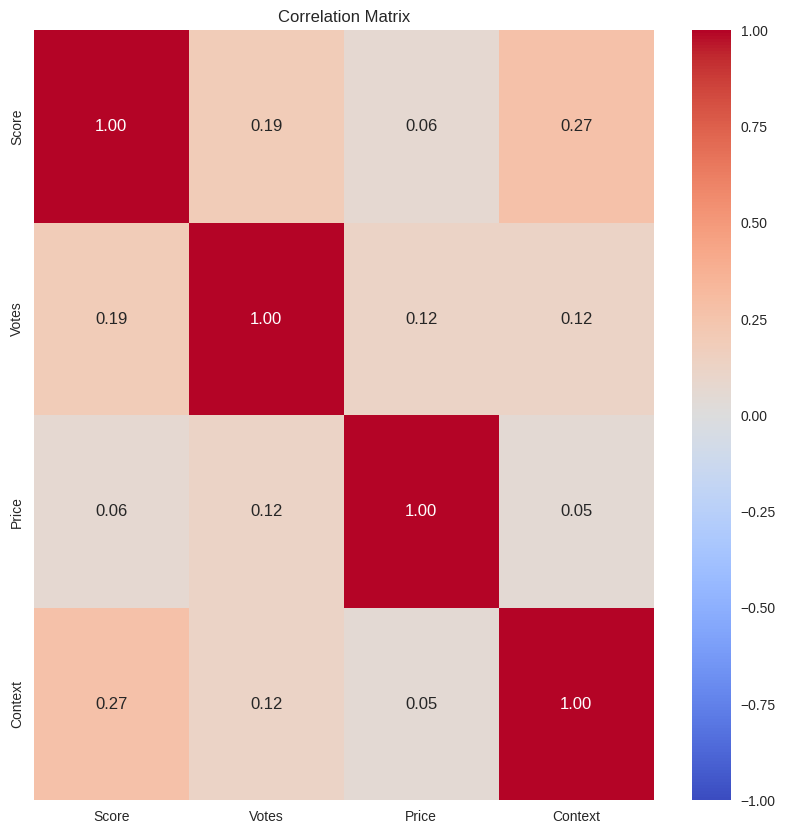

In [19]:
numerical_cols = df.select_dtypes(include=['number']).columns
correlation = df[numerical_cols].corr()
plt.figure(figsize=(10, 10))
sns.heatmap(correlation,
               annot=True,
               cmap='coolwarm',
               fmt=".2f",
               vmin=-1,
               vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [20]:
# 1. Cek apakah ada Model yang sama di Kategori yang sama (Duplikat Kombinasi)
duplicates = df[df.duplicated(subset=['Model', 'Arena_Category'], keep=False)]

print(f"Total baris dengan Model & Kategori sama persis: {len(duplicates)}")

if len(duplicates) > 0:
    print("\n--- Ada duplikat! Ini daftarnya: ---")
    display(duplicates[['Model', 'Arena_Category', 'Votes', 'Score_Num']].sort_values(by=['Arena_Category', 'Model']))
else:
    print("\n✅ TIDAK ADA nama model yang duplikat dalam satu kategori!")
    print("Setiap pasangan (Model + Kategori) adalah 1 baris unik murni dengan nilai Votes bawaannya sendiri.")

Total baris dengan Model & Kategori sama persis: 0

✅ TIDAK ADA nama model yang duplikat dalam satu kategori!
Setiap pasangan (Model + Kategori) adalah 1 baris unik murni dengan nilai Votes bawaannya sendiri.


# **Model AI Paling Populer dari vote  terbanyak**

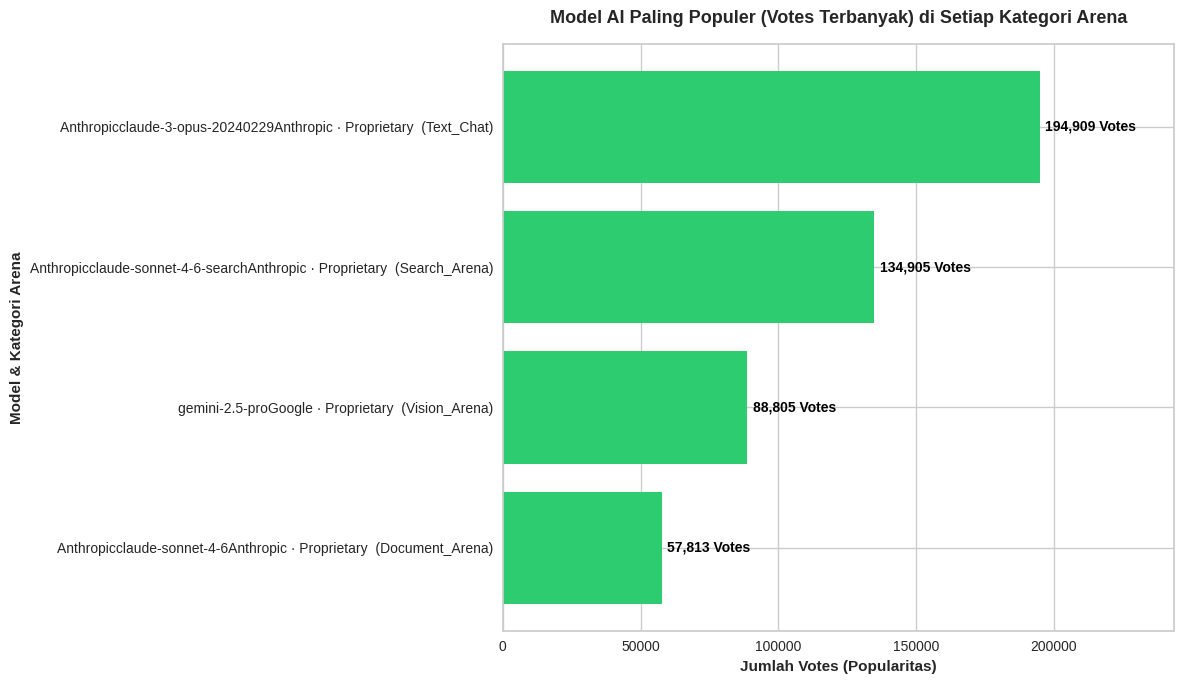

In [21]:
# 1. Ambil 1 model dengan Votes TERBANYAK (paling populer) di setiap Arena_Category
most_popular_per_cat = (
    df.sort_values(by='Votes', ascending=False)
    .groupby('Arena_Category')
    .first()
    .reset_index()
    .sort_values(by='Votes', ascending=False)
)

# 2. Bikin label gabungan: "Nama Model  (Kategori Arena)"
most_popular_per_cat['Label'] = most_popular_per_cat['Model'] + '  (' + most_popular_per_cat['Arena_Category'] + ')'

# 3. Plot dengan Matplotlib
plt.figure(figsize=(12, 7))
bars = plt.barh(most_popular_per_cat['Label'], most_popular_per_cat['Votes'], color='#2ecc71') # Warna hijau populer

# 4. Tambahkan angka jumlah Votes persis di sebelah kanan ujung bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + (most_popular_per_cat['Votes'].max() * 0.01), # Offset proporsional
        bar.get_y() + bar.get_height()/2,
        f'{int(width):,} Votes', # Format angka pakai ribuan (misal: 79,415 Votes)
        va='center',
        ha='left',
        color='black',
        fontweight='bold',
        fontsize=10
    )

# 5. Atur batas sumbu X biar ada ruang buat teks angka
plt.xlim(0, most_popular_per_cat['Votes'].max() * 1.25)

plt.xlabel('Jumlah Votes (Popularitas)', fontsize=11, fontweight='bold')
plt.ylabel('Model & Kategori Arena', fontsize=11, fontweight='bold')
plt.title('Model AI Paling Populer (Votes Terbanyak) di Setiap Kategori Arena', fontsize=13, fontweight='bold', pad=15)
plt.gca().invert_yaxis()  # Biar yang paling populer ada di paling atas

plt.tight_layout()
plt.show()

In [22]:
df.head()

,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,gemini-4-argon-highGoogle · Proprietary,1525.0,4892,6.0,1000000.0,Text_Chat,Google
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.0,6272,12.0,1000000.0,Text_Chat,Anthropic
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.0,79415,15.0,1000000.0,Text_Chat,Anthropic
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.0,40026,30.0,1000000.0,Text_Chat,Anthropic
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.0,65192,15.0,1000000.0,Text_Chat,Anthropic


In [23]:
ACU = df['Arena_Category'].unique()
ACU

array(['Text_Chat', 'Search_Arena', 'Vision_Arena', 'Document_Arena'],
      dtype=object)

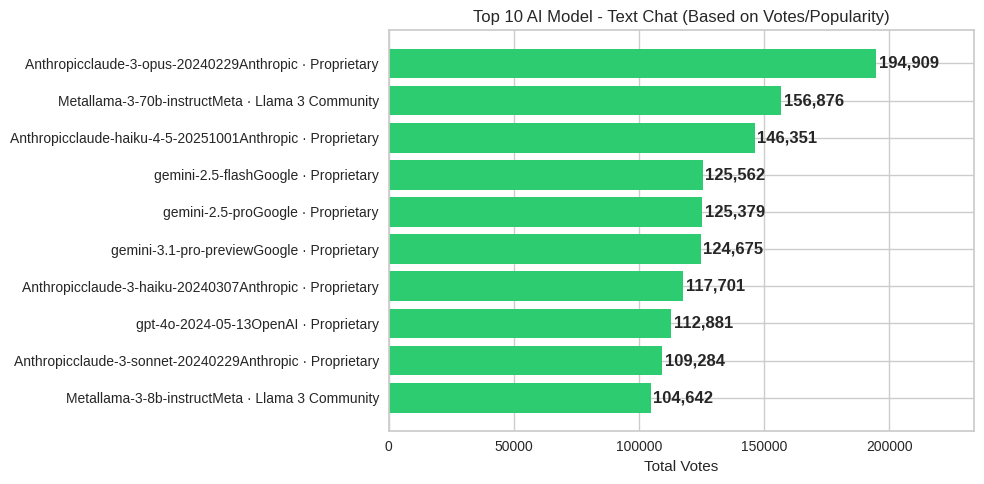

In [24]:
top10_votes_Text_Chat = df[df['Arena_Category'] == 'Text_Chat'].sort_values(by='Votes', ascending=False).head(10)

plt.figure(figsize=(10, 5))
bars = plt.barh(top10_votes_Text_Chat['Model'], top10_votes_Text_Chat['Votes'], color='#2ecc71')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1000, bar.get_y() + bar.get_height()/2, f'{int(w):,}', va='center', ha='left', fontweight='bold')

plt.xlim(0, top10_votes_Text_Chat['Votes'].max() * 1.2)
plt.title('Top 10 AI Model - Text Chat (Based on Votes/Popularity)')
plt.xlabel('Total Votes')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

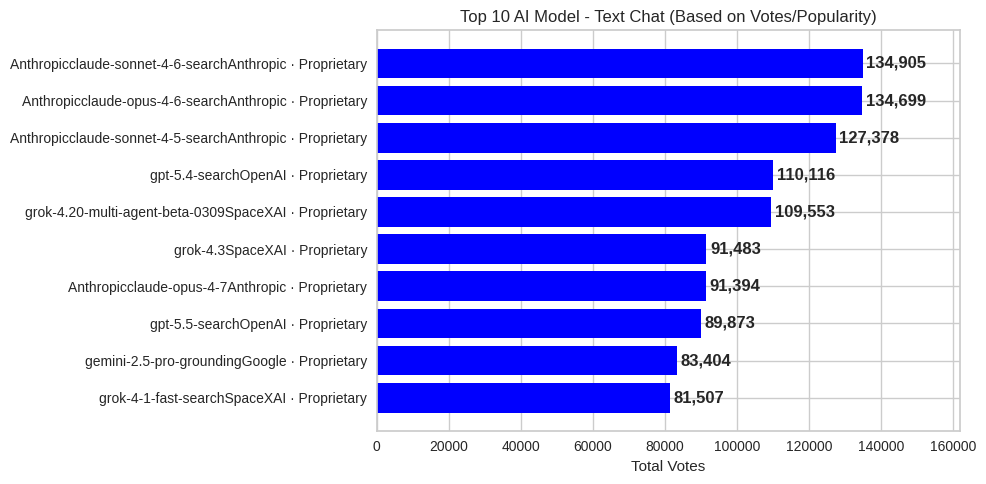

In [25]:
top10_votes_Text_Chat = df[df['Arena_Category'] == 'Search_Arena'].sort_values(by='Votes', ascending=False).head(10)

plt.figure(figsize=(10, 5))
bars = plt.barh(top10_votes_Text_Chat['Model'], top10_votes_Text_Chat['Votes'], color='blue')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1000, bar.get_y() + bar.get_height()/2, f'{int(w):,}', va='center', ha='left', fontweight='bold')

plt.xlim(0, top10_votes_Text_Chat['Votes'].max() * 1.2)
plt.title('Top 10 AI Model - Text Chat (Based on Votes/Popularity)')
plt.xlabel('Total Votes')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

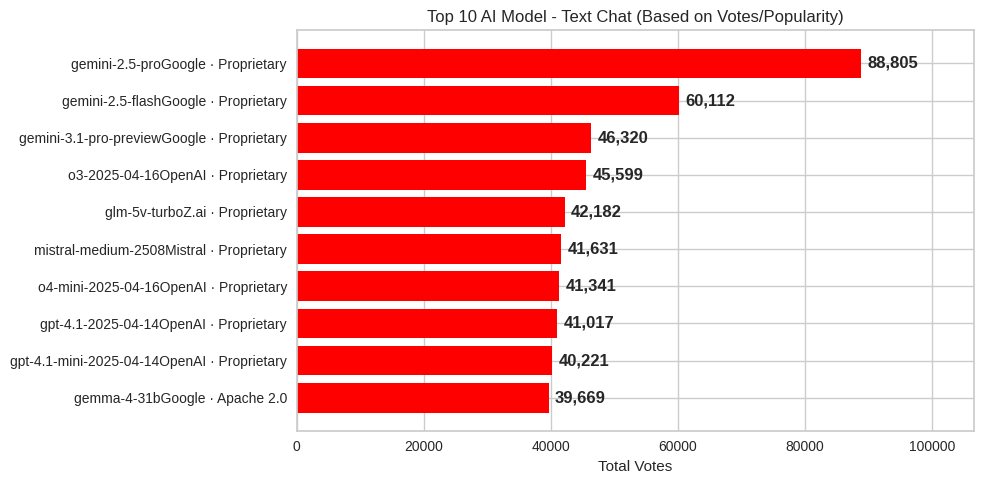

In [26]:
top10_votes_Text_Chat = df[df['Arena_Category'] == 'Vision_Arena'].sort_values(by='Votes', ascending=False).head(10)

plt.figure(figsize=(10, 5))
bars = plt.barh(top10_votes_Text_Chat['Model'], top10_votes_Text_Chat['Votes'], color='Red')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1000, bar.get_y() + bar.get_height()/2, f'{int(w):,}', va='center', ha='left', fontweight='bold')

plt.xlim(0, top10_votes_Text_Chat['Votes'].max() * 1.2)
plt.title('Top 10 AI Model - Text Chat (Based on Votes/Popularity)')
plt.xlabel('Total Votes')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

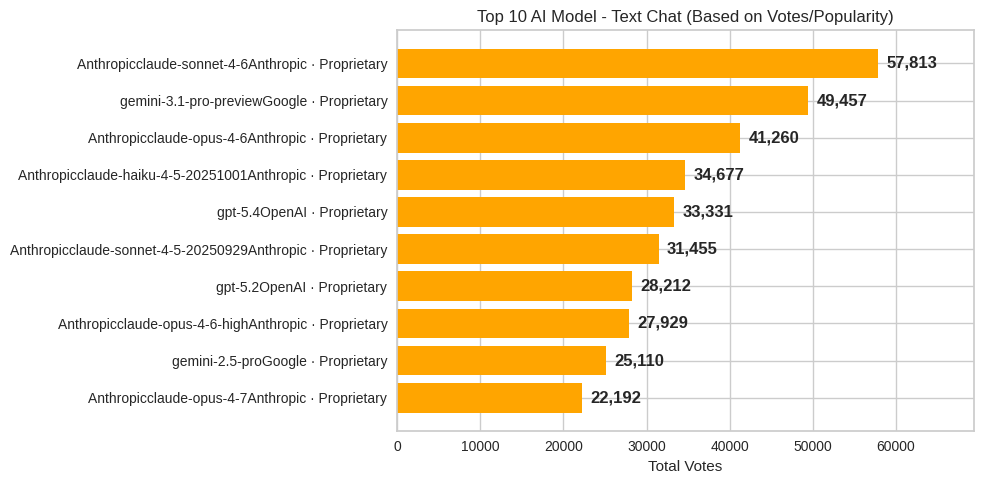

In [27]:
top10_votes_Text_Chat = df[df['Arena_Category'] == 'Document_Arena'].sort_values(by='Votes', ascending=False).head(10)

plt.figure(figsize=(10, 5))
bars = plt.barh(top10_votes_Text_Chat['Model'], top10_votes_Text_Chat['Votes'], color='Orange')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1000, bar.get_y() + bar.get_height()/2, f'{int(w):,}', va='center', ha='left', fontweight='bold')

plt.xlim(0, top10_votes_Text_Chat['Votes'].max() * 1.2)
plt.title('Top 10 AI Model - Text Chat (Based on Votes/Popularity)')
plt.xlabel('Total Votes')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [28]:
# Format tampilan float di Pandas agar hanya menampilkan 2 angka desimal
pd.set_option('display.float_format', lambda x: '%.2f' % x)

In [29]:
df

,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,gemini-4-argon-highGoogle · Proprietary,1525.00,4892,6.00,1000000.00,Text_Chat,Google
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.00,6272,12.00,1000000.00,Text_Chat,Anthropic
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.00,79415,15.00,1000000.00,Text_Chat,Anthropic
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.00,40026,30.00,1000000.00,Text_Chat,Anthropic
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.00,65192,15.00,1000000.00,Text_Chat,Anthropic
...,...,...,...,...,...,...,...
652,gemini-3-flashGoogle · Proprietary,1413.00,7158,1.75,1000000.00,Document_Arena,Google
653,gpt-5.2-highOpenAI · Proprietary,1405.00,7108,3.94,400000.00,Document_Arena,OpenAI
654,gpt-5.1OpenAI · Proprietary,1403.00,8244,2.81,400000.00,Document_Arena,OpenAI
655,gpt-5.5-instantOpenAI · Proprietary,1403.00,8497,17.50,1100000.00,Document_Arena,OpenAI


task: memperlihatkan pengguna lebih condong ke perushaan ai apa?
caranya :
1. diambil dari jumlah vote (semua model yang di miliki suatu perusahaan  di jumlahkan )
2. menampilkan jumlah voting dari pengguna dari masing masing perusahaan (ambil top 10)

In [30]:
Lab = df['Lab'].unique()
Lab

array(['Google', 'Anthropic', 'Meta', 'OpenAI', 'Alibaba Cloud', 'Xiaomi',
       'Zhipu AI (Z.ai)', 'DeepSeek', 'xAI (SpaceX)', 'Baidu',
       'Moonshot AI', 'Tencent', 'StepFun', 'Thinking Machines',
       'MiniMax', 'Mistral AI', 'Meituan', 'Upstage',
       'Other / Open Source', 'Cohere', 'Inception AI', 'Amazon', 'Ai2',
       'NVIDIA', 'IBM', 'AI21 Labs', 'Microsoft', 'Databricks',
       'Perplexity AI'], dtype=object)

In [31]:
jumlah_lab = df['Lab'].nunique()
jumlah_lab

29

/tmp/ipykernel_16012/1478156415.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lab_votes_top10.values, y=lab_votes_top10.index, palette='viridis')


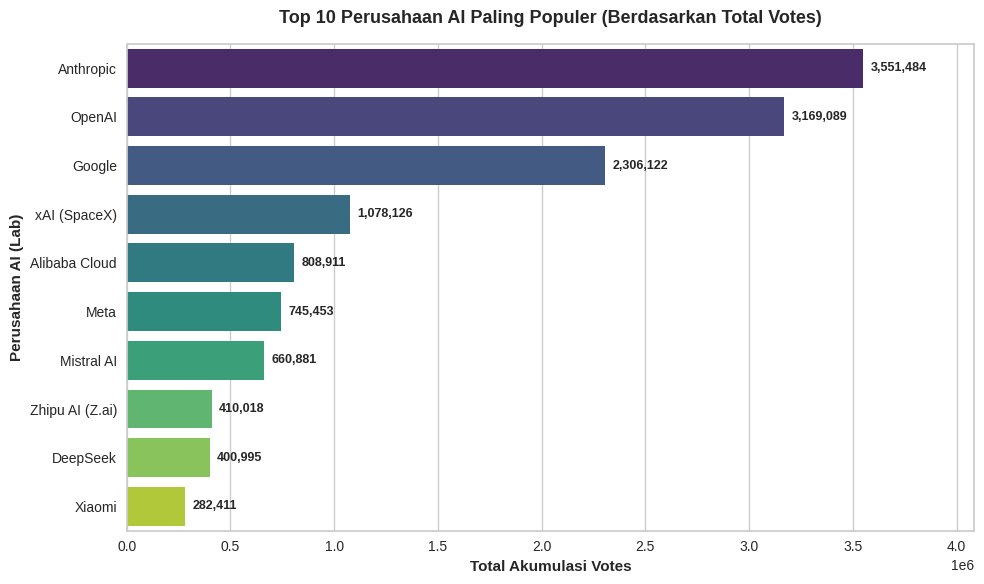

In [32]:
# 1. Ambil TOP 10 Perusahaan AI berdasarkan akumulasi Votes
lab_votes_top10 = df.groupby('Lab')['Votes'].sum().sort_values(ascending=False).head(10)

# 2. Ukuran figure dibuat lebih ringkas dan pas (misal tinggi 6 atau 7 inci)
plt.figure(figsize=(10, 6))

# 3. Horizontal bar chart
sns.barplot(x=lab_votes_top10.values, y=lab_votes_top10.index, palette='viridis')

# 4. Label angka di samping bar
for i, value in enumerate(lab_votes_top10.values):
    plt.text(value + (lab_votes_top10.values.max() * 0.01), i, f'{value:,}', va='center', fontsize=9, fontweight='bold')

plt.title('Top 10 Perusahaan AI Paling Populer (Berdasarkan Total Votes)', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Total Akumulasi Votes', fontsize=11, fontweight='bold')
plt.ylabel('Perusahaan AI (Lab)', fontsize=11, fontweight='bold')
plt.xlim(0, lab_votes_top10.values.max() * 1.15)

plt.tight_layout()
plt.show()

Melihat harga : apakahh score yang dihassilkan oleh Setiap Model AI mempengaruhi harga yang di tawarkan?

In [33]:
Lab = df['Arena_Category'].unique()
Lab

array(['Text_Chat', 'Search_Arena', 'Vision_Arena', 'Document_Arena'],
      dtype=object)

In [34]:
import plotly.express as px

# 1. Ambil TOP 30 Model khusus kategori Text_Chat berdasarkan Score
top30_tc = df[df['Arena_Category'] == 'Text_Chat'].sort_values(by='Score', ascending=False).head(50)

# 2. Bikin Scatter Plot Interaktif menggunakan Plotly
fig = px.scatter(
    top30_tc,
    x='Score',
    y='Price',
    color='Lab',                  # Warna dot berdasarkan Perusahaan AI (Lab)
    hover_name='Model',           # Judul tooltip (Nama Model)
    hover_data={
        'Score': ':.0f',          # Menampilkan Elo Score
        'Price': ':$:.2f',        # Menampilkan Harga ($)
        'Lab': True,              # Menampilkan Nama Lab
        'Arena_Category': False   # Sembunyikan kategori
    },
    title='<b>Hubungan Price vs Performance (Top 30 Model - Text Chat)</b>',
    labels={
        'Score': 'Elo Score (Kepintaran)',
        'Price': 'Rata-Rata Harga ($)',
        'Lab': 'Perusahaan AI (Lab)'
    }
)

# 3. Kustomisasi Dot dan Ukuran Marker
fig.update_traces(
    marker=dict(size=12, symbol='circle', opacity=0.85), # Dot murni dengan sedikit transparansi
    selector=dict(mode='markers')
)

fig.update_layout(
    width=950,
    height=580,
    template='plotly_white',
    legend_title_text='<b>Perusahaan AI (Lab)</b>',
    title_font_size=16
)

# 4. Tampilkan Grafik
fig.show()

In [35]:
# 1. Ambil TOP 30 Model khusus kategori Text_Chat berdasarkan Score
top30_tc = df[df['Arena_Category'] == 'Search_Arena'].sort_values(by='Score', ascending=False).head(50)

# 2. Bikin Scatter Plot Interaktif menggunakan Plotly
fig = px.scatter(
    top30_tc,
    x='Score',
    y='Price',
    color='Lab',                  # Warna dot berdasarkan Perusahaan AI (Lab)
    hover_name='Model',           # Judul tooltip (Nama Model)
    hover_data={
        'Score': ':.0f',          # Menampilkan Elo Score
        'Price': ':$:.2f',        # Menampilkan Harga ($)
        'Lab': True,              # Menampilkan Nama Lab
        'Arena_Category': False   # Sembunyikan kategori
    },
    title='<b>Hubungan Price vs Performance (Top 30 Model - Search_Arena)</b>',
    labels={
        'Score': 'Elo Score (Kepintaran)',
        'Price': 'Rata-Rata Harga ($)',
        'Lab': 'Perusahaan AI (Lab)'
    }
)

# 3. Kustomisasi Dot dan Ukuran Marker
fig.update_traces(
    marker=dict(size=12, symbol='circle', opacity=0.85), # Dot murni dengan sedikit transparansi
    selector=dict(mode='markers')
)

fig.update_layout(
    width=950,
    height=580,
    template='plotly_white',
    legend_title_text='<b>Perusahaan AI (Lab)</b>',
    title_font_size=16
)

# 4. Tampilkan Grafik
fig.show()

In [36]:
# 1. Ambil TOP 30 Model khusus kategori Text_Chat berdasarkan Score
top30_tc = df[df['Arena_Category'] == 'Vision_Arena'].sort_values(by='Score', ascending=False).head(50)

# 2. Bikin Scatter Plot Interaktif menggunakan Plotly
fig = px.scatter(
    top30_tc,
    x='Score',
    y='Price',
    color='Lab',                  # Warna dot berdasarkan Perusahaan AI (Lab)
    hover_name='Model',           # Judul tooltip (Nama Model)
    hover_data={
        'Score': ':.0f',          # Menampilkan Elo Score
        'Price': ':$:.2f',        # Menampilkan Harga ($)
        'Lab': True,              # Menampilkan Nama Lab
        'Arena_Category': False   # Sembunyikan kategori
    },
    title='<b>Hubungan Price vs Performance (Top 30 Model - Vision_Arena)</b>',
    labels={
        'Score': 'Elo Score (Kepintaran)',
        'Price': 'Rata-Rata Harga ($)',
        'Lab': 'Perusahaan AI (Lab)'
    }
)

# 3. Kustomisasi Dot dan Ukuran Marker
fig.update_traces(
    marker=dict(size=12, symbol='circle', opacity=0.85), # Dot murni dengan sedikit transparansi
    selector=dict(mode='markers')
)

fig.update_layout(
    width=950,
    height=580,
    template='plotly_white',
    legend_title_text='<b>Perusahaan AI (Lab)</b>',
    title_font_size=16
)

# 4. Tampilkan Grafik
fig.show()

In [37]:
# 1. Ambil TOP 30 Model khusus kategori Text_Chat berdasarkan Score
top30_tc = df[df['Arena_Category'] == 'Document_Arena'].sort_values(by='Score', ascending=False).head(50)

# 2. Bikin Scatter Plot Interaktif menggunakan Plotly
fig = px.scatter(
    top30_tc,
    x='Score',
    y='Price',
    color='Lab',                  # Warna dot berdasarkan Perusahaan AI (Lab)
    hover_name='Model',           # Judul tooltip (Nama Model)
    hover_data={
        'Score': ':.0f',          # Menampilkan Elo Score
        'Price': ':$:.2f',        # Menampilkan Harga ($)
        'Lab': True,              # Menampilkan Nama Lab
        'Arena_Category': False   # Sembunyikan kategori
    },
    title='<b>Hubungan Price vs Performance (Top 30 Model - Document_Arena)</b>',
    labels={
        'Score': 'Elo Score (Kepintaran)',
        'Price': 'Rata-Rata Harga ($)',
        'Lab': 'Perusahaan AI (Lab)'
    }
)

# 3. Kustomisasi Dot dan Ukuran Marker
fig.update_traces(
    marker=dict(size=12, symbol='circle', opacity=0.85), # Dot murni dengan sedikit transparansi
    selector=dict(mode='markers')
)

fig.update_layout(
    width=950,
    height=580,
    template='plotly_white',
    legend_title_text='<b>Perusahaan AI (Lab)</b>',
    title_font_size=16
)

# 4. Tampilkan Grafik
fig.show()

Score to Vote per category

In [38]:
import plotly.express as px

# 1. Bikin Scatter Plot Score vs Votes yang di-facet (dipecah) per Kategori Arena
fig = px.scatter(
    df,
    x='Score',
    y='Votes',
    color='Lab',                      # Warna dot membedakan Perusahaan AI
    facet_col='Arena_Category',       # Memecah grafik per Kategori Arena
    facet_col_wrap=2,                 # Maksimal 2 kolom per baris biar ga sempit
    hover_name='Model',
    hover_data={
        'Score': ':.0f',
        'Votes': ':,',
        'Lab': True,
        'Arena_Category': False
    },
    title='<b>Hubungan Score vs Votes di Setiap Kategori Arena</b>',
    labels={
        'Score': 'Elo Score',
        'Votes': 'Total Votes',
        'Lab': 'Lab AI'
    }
)

# 2. Merapikan Ukuran Marker dan Layout
fig.update_traces(
    marker=dict(size=9, symbol='circle', opacity=0.8),
    selector=dict(mode='markers')
)

fig.update_layout(
    height=700,
    width=1000,
    template='plotly_white',
    title_font_size=16,
    legend_title_text='<b>Perusahaan AI (Lab)</b>'
)

# Bebaskan sumbu Y per kategori karena skala votes di Text_Chat jauh lebih besar dari arena lain
fig.for_each_yaxis(lambda yaxis: yaxis.update(showticklabels=True, matches=None))

fig.show()

Score to Context

In [39]:
import plotly.express as px

# 1. Bikin Scatter Plot Score vs Context di-facet per Kategori Arena
fig = px.scatter(
    df,
    x='Context',                      # Sumbu X = Context Window (Tokens)
    y='Score',                        # Sumbu Y = Elo Score (Kepintaran)
    color='Lab',                      # Warna dot berdasarkan Perusahaan AI
    facet_col='Arena_Category',       # Dipecah per Kategori Arena
    facet_col_wrap=2,                 # Maksimal 2 kolom per baris
    hover_name='Model',
    hover_data={
        'Context': ':,',              # Format Context dengan pemisah ribuan
        'Score': ':.0f',              # Elo Score
        'Votes': ':,',                # Total Votes
        'Lab': True,
        'Arena_Category': False
    },
    title='<b>Hubungan Context Window vs Elo Score di Setiap Kategori Arena</b>',
    labels={
        'Context': 'Context Window (Tokens)',
        'Score': 'Elo Score (Kepintaran)',
        'Lab': 'Lab AI'
    }
)

# 2. Merapikan Ukuran Dot/Marker
fig.update_traces(
    marker=dict(size=9, symbol='circle', opacity=0.8),
    selector=dict(mode='markers')
)

# 3. Kunci Biar Label Sumbu X dan Y Tampil Lengkap di Semua Sub-plot
fig.for_each_xaxis(lambda xaxis: xaxis.update(showticklabels=True))
fig.for_each_yaxis(lambda yaxis: yaxis.update(showticklabels=True, matches=None))

fig.update_layout(
    height=750,
    width=980,
    template='plotly_white',
    title_font_size=16,
    legend_title_text='<b>Perusahaan AI (Lab)</b>'
)

fig.show()

Vote to Price

In [40]:
import plotly.express as px

# 1. Bikin Scatter Plot Votes vs Price yang di-facet per Kategori Arena
fig = px.scatter(
    df,
    x='Price',                        # Sumbu X = Rata-Rata Harga ($)
    y='Votes',                        # Sumbu Y = Total Votes (Popularitas)
    color='Lab',                      # Warna dot berdasarkan Perusahaan AI
    facet_col='Arena_Category',       # Dipecah per Kategori Arena
    facet_col_wrap=2,                 # Maksimal 2 kolom per baris
    hover_name='Model',
    hover_data={
        'Price': ':$:.2f',            # Format $ untuk Harga
        'Votes': ':,',                # Format ribuan untuk Votes
        'Score': ':.0f',              # Elo Score
        'Lab': True,
        'Arena_Category': False
    },
    title='<b>Hubungan Harga (Price) vs Popularitas (Votes) di Setiap Kategori Arena</b>',
    labels={
        'Price': 'Rata-Rata Harga ($)',
        'Votes': 'Total Votes (Popularitas)',
        'Lab': 'Lab AI'
    }
)

# 2. Merapikan Ukuran Marker
fig.update_traces(
    marker=dict(size=9, symbol='circle', opacity=0.8),
    selector=dict(mode='markers')
)

# 3. Kunci Biar Label Sumbu X dan Y Tampil Lengkap di Semua Sub-plot
fig.for_each_xaxis(lambda xaxis: xaxis.update(showticklabels=True))
fig.for_each_yaxis(lambda yaxis: yaxis.update(showticklabels=True, matches=None))

fig.update_layout(
    height=750,
    width=980,
    template='plotly_white',
    title_font_size=16,
    legend_title_text='<b>Perusahaan AI (Lab)</b>'
)

fig.show()

Vote to Context

In [41]:
import plotly.express as px

# 1. Bikin Scatter Plot Votes vs Context di-facet per Kategori Arena
fig = px.scatter(
    df,
    x='Context',                      # Sumbu X = Context Window (Tokens)
    y='Votes',                        # Sumbu Y = Total Votes (Popularitas)
    color='Lab',                      # Warna dot berdasarkan Perusahaan AI
    facet_col='Arena_Category',       # Dipecah per Kategori Arena
    facet_col_wrap=2,                 # Maksimal 2 kolom per baris
    hover_name='Model',
    hover_data={
        'Context': ':,',              # Format angka Context dengan ribuan
        'Votes': ':,',                # Format ribuan untuk Votes
        'Score': ':.0f',              # Elo Score
        'Lab': True,
        'Arena_Category': False
    },
    title='<b>Hubungan Context Window vs Popularitas (Votes) di Setiap Kategori Arena</b>',
    labels={
        'Context': 'Context Window (Tokens)',
        'Votes': 'Total Votes (Popularitas)',
        'Lab': 'Lab AI'
    }
)

# 2. Merapikan Ukuran Marker
fig.update_traces(
    marker=dict(size=9, symbol='circle', opacity=0.8),
    selector=dict(mode='markers')
)

# 3. Kunci Biar Label Sumbu X dan Y Tampil Lengkap di Semua Sub-plot
fig.for_each_xaxis(lambda xaxis: xaxis.update(showticklabels=True))
fig.for_each_yaxis(lambda yaxis: yaxis.update(showticklabels=True, matches=None))

fig.update_layout(
    height=750,
    width=980,
    template='plotly_white',
    title_font_size=16,
    legend_title_text='<b>Perusahaan AI (Lab)</b>'
)

fig.show()

In [42]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Score,475.00,1318.02,124.35,881.00,1227.00,1319.00,1430.50,1525.00
Votes,475.00,31064.71,29657.88,823.00,8379.50,23273.00,42715.50,194909.00
Price,475.00,5.73,10.96,0.00,0.65,1.88,6.00,112.50
Context,475.00,503759.37,445912.37,2000.00,131100.00,262100.00,1000000.00,2100000.00


In [43]:
le = LabelEncoder()
df['Lab'] = le.fit_transform(df['Lab'])
df

,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,gemini-4-argon-highGoogle · Proprietary,1525.00,4892,6.00,1000000.00,Text_Chat,9
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.00,6272,12.00,1000000.00,Text_Chat,4
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.00,79415,15.00,1000000.00,Text_Chat,4
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.00,40026,30.00,1000000.00,Text_Chat,4
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.00,65192,15.00,1000000.00,Text_Chat,4
...,...,...,...,...,...,...,...
652,gemini-3-flashGoogle · Proprietary,1413.00,7158,1.75,1000000.00,Document_Arena,9
653,gpt-5.2-highOpenAI · Proprietary,1405.00,7108,3.94,400000.00,Document_Arena,19
654,gpt-5.1OpenAI · Proprietary,1403.00,8244,2.81,400000.00,Document_Arena,19
655,gpt-5.5-instantOpenAI · Proprietary,1403.00,8497,17.50,1100000.00,Document_Arena,19


In [44]:
le = LabelEncoder()
df['Arena_Category'] = le.fit_transform(df['Arena_Category'])
df.head()

,Model,Score,Votes,Price,Context,Arena_Category,Lab
0,gemini-4-argon-highGoogle · Proprietary,1525.00,4892,6.00,1000000.00,2,9
1,Anthropicclaude-opus-5.5-highAnthropic · Propr...,1507.00,6272,12.00,1000000.00,2,4
2,Anthropicclaude-opus-4-6-highAnthropic · Propr...,1504.00,79415,15.00,1000000.00,2,4
3,Anthropicclaude-fable-5-highAnthropic · Propri...,1504.00,40026,30.00,1000000.00,2,4
4,Anthropicclaude-opus-4-7-highAnthropic · Propr...,1501.00,65192,15.00,1000000.00,2,4


In [47]:
features = ['Score', 'Context', 'Votes', 'Price', 'Arena_Category' ,'Lab']
X = df[features]

Rscale = RobustScaler()
X_scaled = Rscale.fit_transform(X)
print('Scaling data sudah di lakukan dengan robust scaler skrng masuk ke Elbow dan KMeans')

Scaling data sudah di lakukan dengan robust scaler skrng masuk ke Elbow dan KMeans


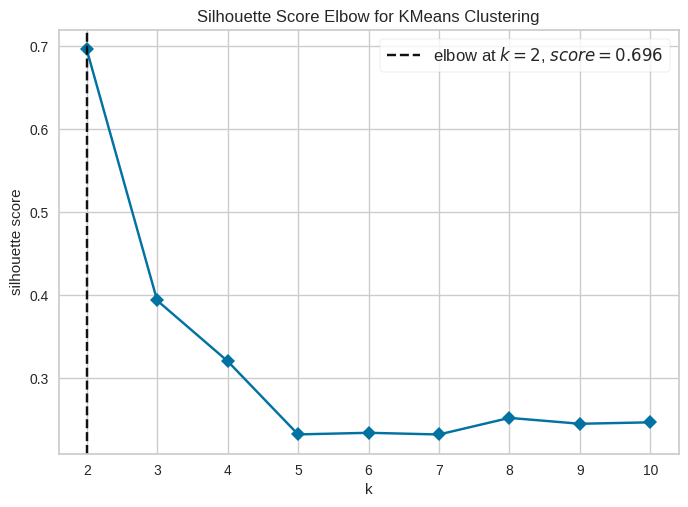

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [59]:
model = KMeans()

visualizer = KElbowVisualizer(model, k=(2,11), metric='silhouette', timings=False)

visualizer.fit(X_scaled)

visualizer.show()


In [52]:
model = KMeans(n_clusters=2, random_state=42)

model.fit(X_scaled)

KMeans(n_clusters=2, random_state=42)

In [53]:
joblib.dump(model, "model_clustering.h5")

['model_clustering.h5']

In [54]:
labels = model.labels_
score = silhouette_score(X_scaled, labels)
print("Silhouette Score", score)

Silhouette Score 0.8617224987057412
